# Model Evaluation, Comparison & Diagnostic Results

This notebook provides a comprehensive evaluation and diagnostic suite for all trained final models developed in `ML.ipynb`:
1. **Random Forest** (`random_forest_best_pipeline.pkl`)
2. **Support Vector Machine (SVM)** (`svm_best_pipeline.pkl`)
3. **XGBoost Classifier** (`xgboost_best_pipeline.pkl`)

---

### Objectives & Evaluation Framework:
- **Model Ingestion**: Load the persisted pipelines, held-out test set (`X_test`, `y_test`), and training splits (`X_train`, `y_train`).
- **Comprehensive Metric Suite**: Calculate and tabulate:
    
    Accuracy, Balanced Accuracy, Precision, Recall/Sensitivity, Specificity, F1-Score, F2-Score (churn-focused), ROC-AUC, PR-AUC / Average Precision, Matthews Correlation Coefficient (MCC), Log-Loss, and Brier Score.
- **Diagnostic Visualizations & Comparative Curves**:
  - Receiver Operating Characteristic (ROC) Curves with AUC comparisons.
  - Precision-Recall (PR) Curves with No-Skill positive class baseline.
  - Side-by-Side Confusion Matrices (Raw Counts & Recall Normalized).
  - Multi-Metric Comparison Bar Charts & Performance Tables.
  - Probability Calibration & Reliability Curves (Brier Score analysis).
  - Decision Threshold Tuning Curves (Precision-Recall-F1 vs. Threshold).
- **Interpretability & Feature Importance**:
  - Tree-based Feature Importances (Random Forest & XGBoost).
  - Model-agnostic Permutation Importance on the held-out test set across all 3 models.
- **Segmented / Subgroup Error Analysis**:
  - Performance sliced across business segments (Contract Type, Internet Service, Tenure Cohorts).
- **Churn Economics & Cost-Benefit Analysis**:
  - Cumulative Gains and Lift Analysis.
  - Financial Return / Profit Optimization Curves for targeted customer retention campaigns.

## When using Google colab

In [2]:
# Mount Google Drive
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
    print("Google Drive mounted successfully.")
except ImportError:
    IN_COLAB = False
    print("Not running in Google Colab environment. Using local directory paths.")

Mounted at /content/drive
Google Drive mounted successfully.


In [3]:
if IN_COLAB:
    !pip install -q xgboost scikit-learn>=1.9.0 pandas pyarrow fastparquet joblib

## 1. Environment Configuration & Path Setup

In [4]:
# Check environment and configure paths for local execution or Google Colab
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
    print("Running in Google Colab environment.")
except ImportError:
    IN_COLAB = False
    print("Running in local environment.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Running in Google Colab environment.


In [5]:
# Core libraries
import os, json, joblib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn Metrics & Inspection
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
    confusion_matrix,
    classification_report,
    brier_score_loss,
    log_loss,
    matthews_corrcoef
)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

In [6]:
# Configuration & Styling
warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams.update({
    "figure.titlesize": 16,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.autolayout": False,
    "figure.dpi": 110
})

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

# Color Palette for consistent model visualization
MODEL_COLORS = {
    "Random Forest": "#2b5c8f",
    "SVM": "#e76f51",
    "XGBoost": "#2a9d8f"
}

TARGET = "Churn"
RANDOM_STATE = 42

In [7]:
# Define Directory Paths
if IN_COLAB:
    PROJECT_ROOT = "/content/drive/MyDrive/Projects/Week1and2Project"
else:
    PROJECT_ROOT = ".."

DATAFRAMES_DIR = os.path.join(PROJECT_ROOT, "DataFrames")
MODELS_DIR = os.path.join(PROJECT_ROOT, "Models")
RESULTS_DIR = os.path.join(PROJECT_ROOT, "Results")
CV_RESULTS_DIR = os.path.join(RESULTS_DIR, "cv_results")
METRICS_DIR = os.path.join(RESULTS_DIR, "metrics")
FIGURES_DIR = os.path.join(RESULTS_DIR, "figures")

os.makedirs(FIGURES_DIR, exist_ok=True)

print(f"Project Root: {os.path.abspath(PROJECT_ROOT)}")
print(f"Models Directory: {os.path.abspath(MODELS_DIR)}")
print(f"DataFrames Directory: {os.path.abspath(DATAFRAMES_DIR)}")
print(f"Results Directory: {os.path.abspath(RESULTS_DIR)}")

Project Root: /content/drive/MyDrive/Projects/Week1and2Project
Models Directory: /content/drive/MyDrive/Projects/Week1and2Project/Models
DataFrames Directory: /content/drive/MyDrive/Projects/Week1and2Project/DataFrames
Results Directory: /content/drive/MyDrive/Projects/Week1and2Project/Results


## 2. Load Evaluation Datasets and Trained Models

In [8]:
# Loading Parquet Splits

def _to_1d_target(y):
    if isinstance(y, pd.DataFrame):
        y = y[TARGET] if TARGET in y.columns else y.iloc[:, 0]
    y = y.squeeze()
    if not pd.api.types.is_numeric_dtype(y):
        y = y.map({"No": 0, "Yes": 1, "0": 0, "1": 1, False: 0, True: 1}).astype(int)
    return y

X_train = pd.read_parquet(os.path.join(DATAFRAMES_DIR, "X_train.parquet"))
y_train = _to_1d_target(pd.read_parquet(os.path.join(DATAFRAMES_DIR, "y_train.parquet")))

X_test = pd.read_parquet(os.path.join(DATAFRAMES_DIR, "X_test.parquet"))
y_test = _to_1d_target(pd.read_parquet(os.path.join(DATAFRAMES_DIR, "y_test.parquet")))

print(f"Train samples: {len(X_train):,} (Features: {X_train.shape[1]})")
print(f"Test samples:  {len(X_test):,} (Features: {X_test.shape[1]})")
print(f"Test Positive Class (Churn=1) Proportion: {y_test.mean():.2%}")

Train samples: 5,616 (Features: 25)
Test samples:  1,405 (Features: 25)
Test Positive Class (Churn=1) Proportion: 26.48%


In [9]:
# Model registry mapping
model_files = {
    "Random Forest": os.path.join(MODELS_DIR, "random_forest_best_pipeline.pkl"),
    "SVM": os.path.join(MODELS_DIR, "svm_best_pipeline.pkl"),
    "XGBoost": os.path.join(MODELS_DIR, "xgboost_best_pipeline.pkl")
}

models = {}
for name, path in model_files.items():
    if os.path.exists(path):
        models[name] = joblib.load(path)
        print(f"✓ Loaded {name} from {os.path.basename(path)}")
    else:
        print(f"✗ Model file not found: {path}")

if len(models) == 0:
    raise FileNotFoundError("No models found in Models directory. Please ensure models are trained and saved.")
print(f"\nSuccessfully loaded {len(models)} model pipeline(s): {list(models.keys())}")

✓ Loaded Random Forest from random_forest_best_pipeline.pkl
✓ Loaded SVM from svm_best_pipeline.pkl
✓ Loaded XGBoost from xgboost_best_pipeline.pkl

Successfully loaded 3 model pipeline(s): ['Random Forest', 'SVM', 'XGBoost']


## 3. Comprehensive Performance Metrics & Evaluation Table

We evaluate each model across multiple performance dimensions:
- **Discrimination**: ROC-AUC, PR-AUC / Average Precision
- **Classification Trade-offs**: Precision, Recall, Specificity, F1-Score, F2-Score (prioritizing recall for retention)
- **Overall Accuracy**: Accuracy, Balanced Accuracy, Matthews Correlation Coefficient (MCC)
- **Probabilistic Quality**: Brier Score, Log-Loss
- **Generalization**: Train vs. Test ROC-AUC Gap

In [10]:
# Generate predictions, probabilities, and compute full evaluation metrics
predictions = {}
probabilities = {}
train_probabilities = {}
detailed_metrics = []

for name, pipeline in models.items():
    # Test set predictions & probabilities
    y_pred = pipeline.predict(X_test)
    y_proba = pipeline.predict_proba(X_test)[:, 1]

    # Train set probabilities for overfitting check
    y_train_proba = pipeline.predict_proba(X_train)[:, 1]
    y_train_pred = pipeline.predict(X_train)

    predictions[name] = y_pred
    probabilities[name] = y_proba
    train_probabilities[name] = y_train_proba

    # Confusion matrix values: TN, FP, FN, TP
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0

    # Cross-validation score from saved cv_results if available
    cv_file = os.path.join(CV_RESULTS_DIR, f"{name.lower().replace(' ', '_')}_cv_results.csv")
    if os.path.exists(cv_file):
        cv_df = pd.read_csv(cv_file)
        best_cv_roc_auc = cv_df["mean_test_roc_auc"].max()
    else:
        best_cv_roc_auc = np.nan

    metrics_dict = {
        "Model": name,
        "ROC-AUC": roc_auc_score(y_test, y_proba),
        "PR-AUC (AP)": average_precision_score(y_test, y_proba),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "F2-Score": fbeta_score(y_test, y_pred, beta=2, zero_division=0),
        "Recall (Sensitivity)": recall_score(y_test, y_pred, zero_division=0),
        "Specificity": specificity,
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
        "Accuracy": accuracy_score(y_test, y_pred),
        "MCC": matthews_corrcoef(y_test, y_pred),
        "Brier Score": brier_score_loss(y_test, y_proba),
        "Log-Loss": log_loss(y_test, y_proba),
        "Train ROC-AUC": roc_auc_score(y_train, y_train_proba),
        "CV ROC-AUC": best_cv_roc_auc,
        "Train-Test ROC Gap": roc_auc_score(y_train, y_train_proba) - roc_auc_score(y_test, y_proba)
    }
    detailed_metrics.append(metrics_dict)

results_df = pd.DataFrame(detailed_metrics).set_index("Model")
results_df = results_df.sort_values(by="ROC-AUC", ascending=False)

# Save evaluation summary table
results_df.to_csv(os.path.join(RESULTS_DIR, "detailed_model_evaluation.csv"))

# Display formatted styled comparison table
display(results_df.style.format("{:.4f}").background_gradient(cmap="Blues", subset=["ROC-AUC", "PR-AUC (AP)", "F1-Score", "F2-Score", "Recall (Sensitivity)"]))

,ROC-AUC,PR-AUC (AP),F1-Score,F2-Score,Recall (Sensitivity),Specificity,Precision,Balanced Accuracy,Accuracy,MCC,Brier Score,Log-Loss,Train ROC-AUC,CV ROC-AUC,Train-Test ROC Gap
Model,,,,,,,,,,,,,,,
XGBoost,0.8435,0.6566,0.6267,0.6994,0.7581,0.7619,0.5341,0.7600,0.7609,0.4736,0.1581,0.4726,0.9015,0.8506,0.0580
Random Forest,0.8429,0.6611,0.6320,0.7076,0.7688,0.7609,0.5366,0.7649,0.7630,0.4817,0.1577,0.4725,0.8902,0.8485,0.0473
SVM,0.8373,0.6282,0.5942,0.7130,0.8226,0.6592,0.4650,0.7409,0.7025,0.4260,0.1435,0.4373,0.8498,0.8464,0.0126


## 4. Model Comparison & Diagnostic Visualizations

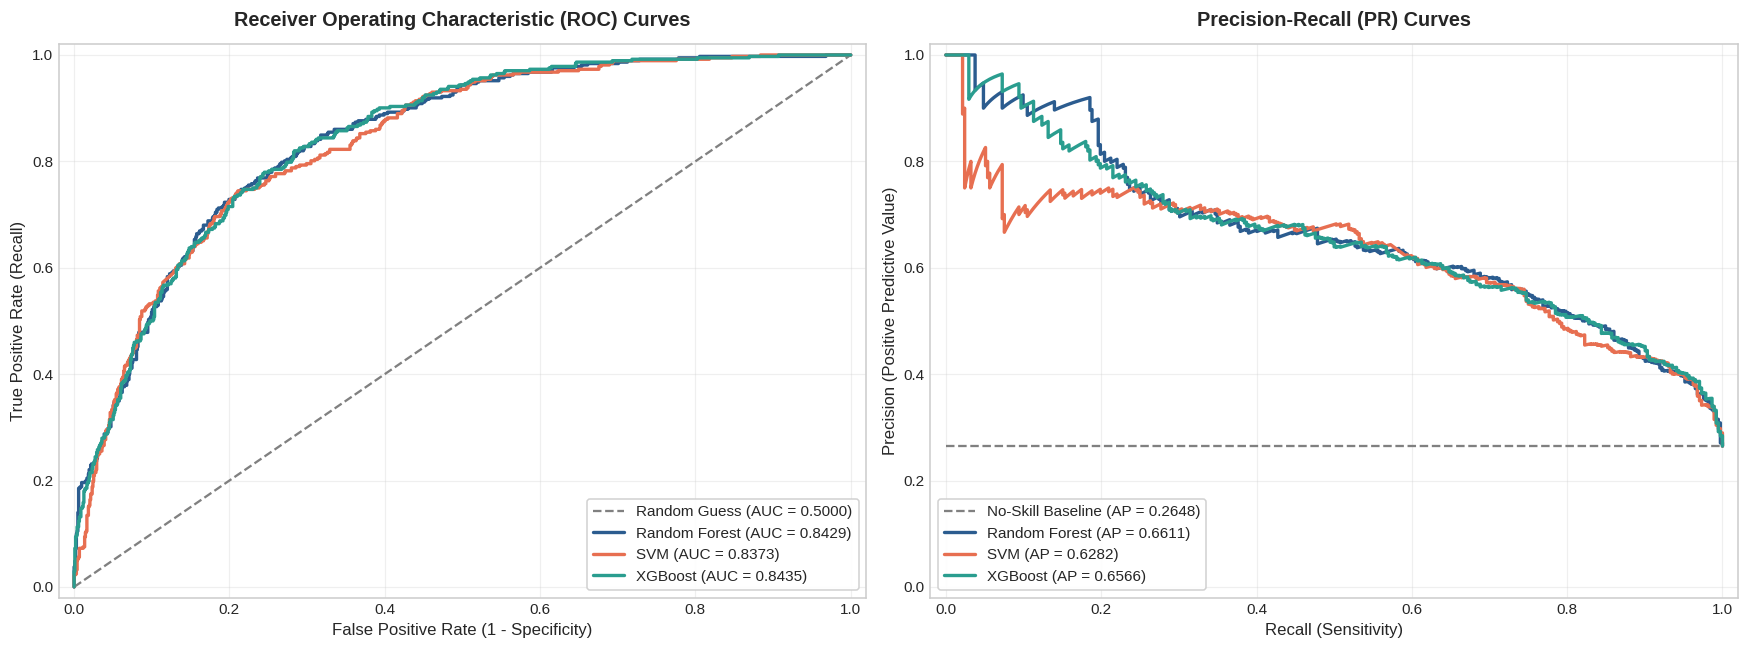

In [11]:
# Visualizing ROC and Precision-Recall Curves Side-by-Side
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(16, 6))

# 1. ROC Curves
ax_roc.plot([0, 1], [0, 1], linestyle="--", color="gray", lw=1.5, label="Random Guess (AUC = 0.5000)")
for name, y_proba in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc_val = roc_auc_score(y_test, y_proba)
    ax_roc.plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.4f})", color=MODEL_COLORS.get(name, "C0"), lw=2.2)

ax_roc.set_title("Receiver Operating Characteristic (ROC) Curves", fontweight="bold", pad=12)
ax_roc.set_xlabel("False Positive Rate (1 - Specificity)")
ax_roc.set_ylabel("True Positive Rate (Recall)")
ax_roc.set_xlim([-0.02, 1.02])
ax_roc.set_ylim([-0.02, 1.02])
ax_roc.legend(loc="lower right", frameon=True, framealpha=0.9)
ax_roc.grid(True, alpha=0.3)

# 2. Precision-Recall Curves
no_skill_rate = y_test.mean()
ax_pr.plot([0, 1], [no_skill_rate, no_skill_rate], linestyle="--", color="gray", lw=1.5,
            label=f"No-Skill Baseline (AP = {no_skill_rate:.4f})")
for name, y_proba in probabilities.items():
    prec, rec, _ = precision_recall_curve(y_test, y_proba)
    ap_val = average_precision_score(y_test, y_proba)
    ax_pr.plot(rec, prec, label=f"{name} (AP = {ap_val:.4f})", color=MODEL_COLORS.get(name, "C0"), lw=2.2)

ax_pr.set_title("Precision-Recall (PR) Curves", fontweight="bold", pad=12)
ax_pr.set_xlabel("Recall (Sensitivity)")
ax_pr.set_ylabel("Precision (Positive Predictive Value)")
ax_pr.set_xlim([-0.02, 1.02])
ax_pr.set_ylim([-0.02, 1.02])
ax_pr.legend(loc="lower left", frameon=True, framealpha=0.9)
ax_pr.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "roc_and_pr_curves.png"), dpi=300, bbox_inches="tight")
plt.show()

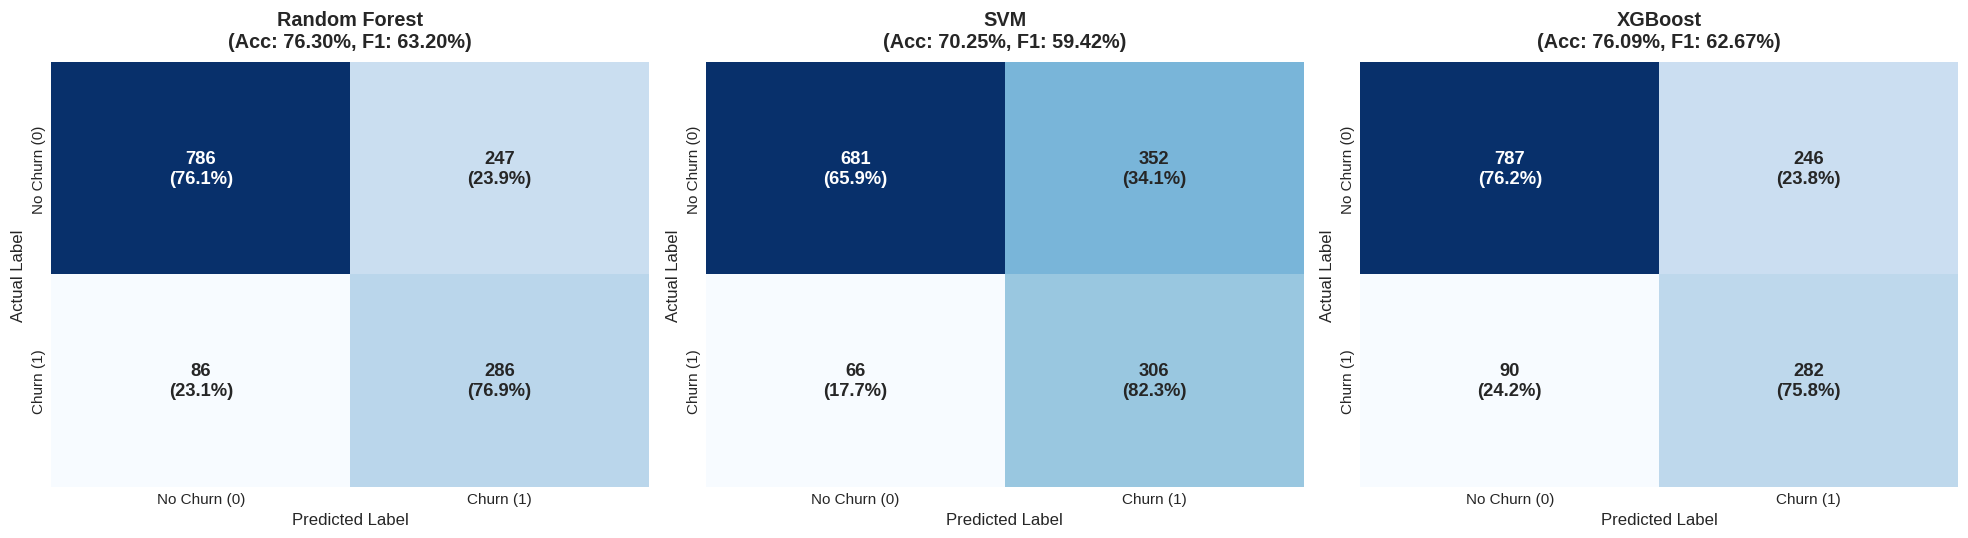

In [12]:
# Side-by-Side Confusion Matrices (Raw Counts & Percentages)
n_models = len(models)
fig, axes = plt.subplots(1, n_models, figsize=(6 * n_models, 5))
if n_models == 1:
    axes = [axes]

class_names = ["No Churn (0)", "Churn (1)"]

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    cm_norm = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]

    # Custom annotations showing raw count and class recall %
    annot = np.empty_like(cm).astype(str)
    for i in range(2):
        for j in range(2):
            annot[i, j] = f"{cm[i, j]:,}\n({cm_norm[i, j]:.1%})"

    sns.heatmap(cm, annot=annot, fmt="", cmap="Blues", cbar=False, ax=ax,
                annot_kws={"size": 12, "weight": "bold"},
                xticklabels=class_names, yticklabels=class_names)

    tn, fp, fn, tp = cm.ravel()
    ax.set_title(f"{name}\n(Acc: {accuracy_score(y_test, y_pred):.2%}, F1: {f1_score(y_test, y_pred):.2%})",
                 fontweight="bold", pad=10)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "confusion_matrices.png"), dpi=300, bbox_inches="tight")
plt.show()

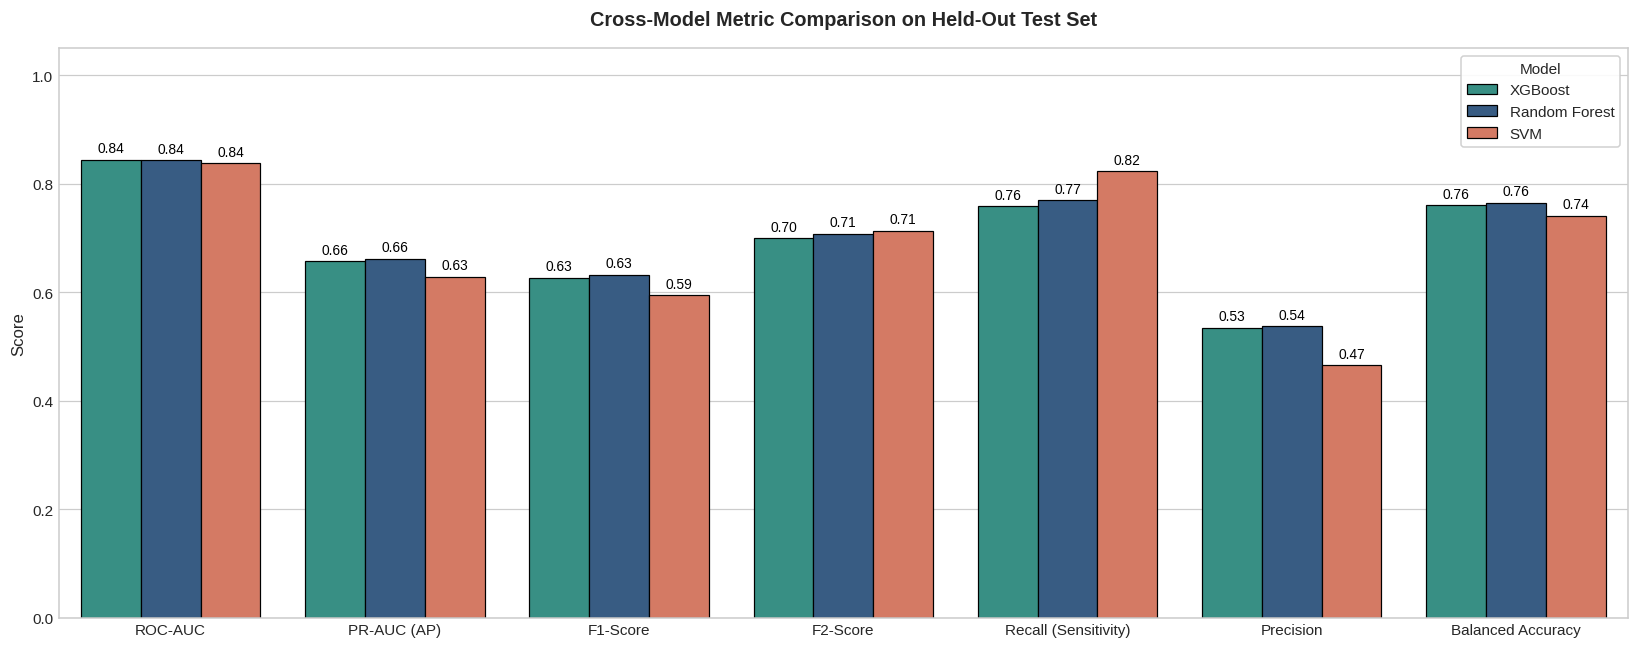

In [13]:
# Grouped Bar Chart comparing core classification metrics
comparison_metrics = ["ROC-AUC", "PR-AUC (AP)", "F1-Score", "F2-Score", "Recall (Sensitivity)", "Precision", "Balanced Accuracy"]
plot_df = results_df[comparison_metrics].reset_index().melt(id_vars="Model", var_name="Metric", value_name="Score")

plt.figure(figsize=(15, 6))
bar_plot = sns.barplot(
    data=plot_df,
    x="Metric",
    y="Score",
    hue="Model",
    palette=MODEL_COLORS,
    edgecolor="black",
    linewidth=0.8
)

for p in bar_plot.patches:
    h = p.get_height()
    if not np.isnan(h) and h > 0:
        bar_plot.annotate(f"{h:.2f}",
                          (p.get_x() + p.get_width() / 2., h),
                          ha='center', va='bottom',
                          fontsize=9, color='black',
                          xytext=(0, 3),
                          textcoords='offset points')

plt.title("Cross-Model Metric Comparison on Held-Out Test Set", fontweight="bold", pad=15)
plt.ylabel("Score")
plt.xlabel("")
plt.ylim(0, 1.05)
plt.legend(title="Model", frameon=True, framealpha=0.9, loc="upper right")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "metric_comparison_bars.png"), dpi=300, bbox_inches="tight")
plt.show()

## 5. Decision Threshold Optimization & Trade-off Analysis

In customer churn prediction, the default 0.50 probability threshold is rarely optimal for business operations:
- Lowering the threshold increases **Recall** (catching more churners at the expense of false positives).
- Increasing the threshold increases **Precision** (avoiding wasted retention budget).

Here we analyze how Precision, Recall, and F1 vary continuously across decision thresholds $[0.05, 0.95]$.

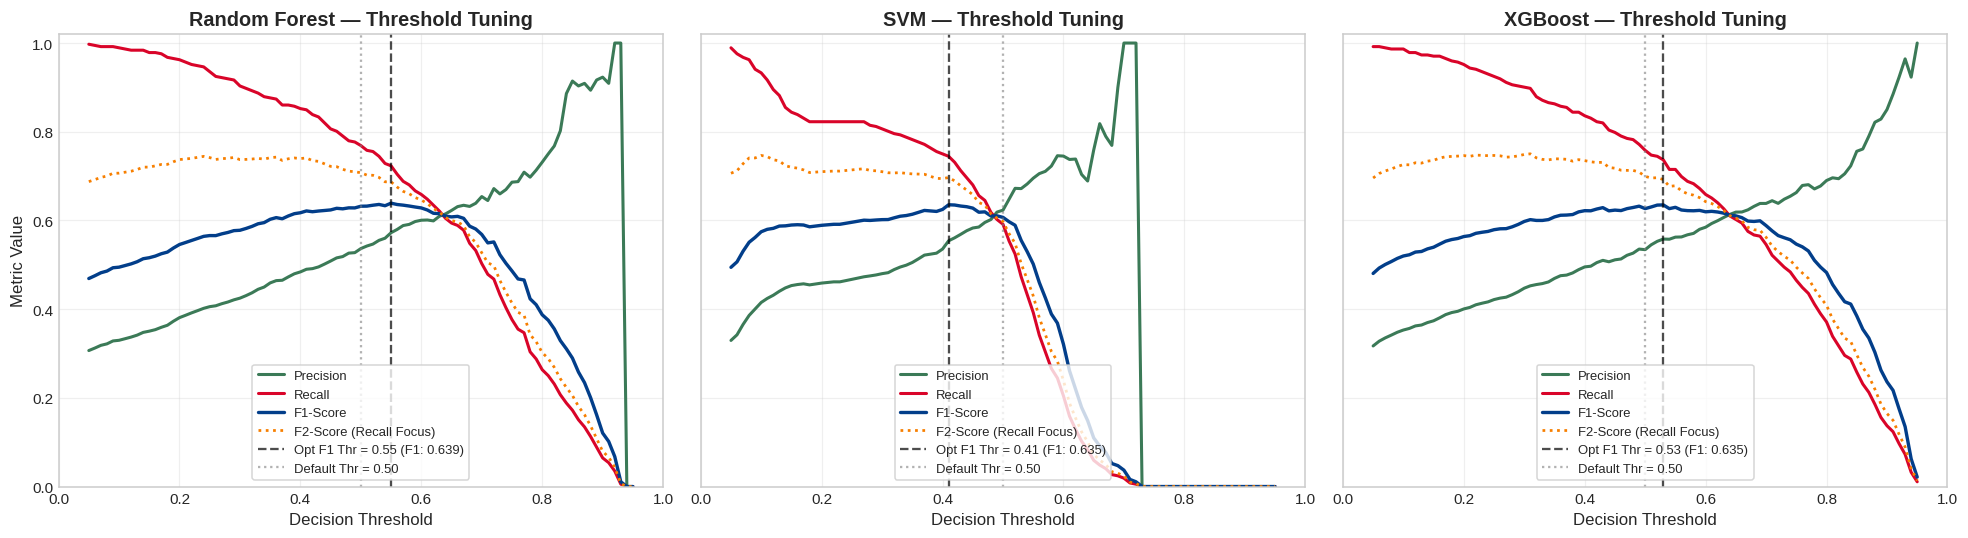

,Optimal Threshold (Max F1),Max F1-Score,Precision at Opt,Recall at Opt
Model,,,,
Random Forest,0.5500,0.6390,0.5723,0.7231
SVM,0.4100,0.6353,0.5540,0.7446
XGBoost,0.5300,0.6350,0.5580,0.7366


In [14]:
# Precision, Recall & F1 Curves vs Decision Threshold
thresholds = np.linspace(0.05, 0.95, 91)

fig, axes = plt.subplots(1, len(models), figsize=(6 * len(models), 5), sharey=True)
if len(models) == 1:
    axes = [axes]

optimal_thresholds = {}

for ax, (name, y_proba) in zip(axes, probabilities.items()):
    prec_list, rec_list, f1_list, f2_list = [], [], [], []

    for t in thresholds:
        y_p = (y_proba >= t).astype(int)
        p = precision_score(y_test, y_p, zero_division=0)
        r = recall_score(y_test, y_p, zero_division=0)
        f1 = f1_score(y_test, y_p, zero_division=0)
        f2 = fbeta_score(y_test, y_p, beta=2, zero_division=0)
        prec_list.append(p)
        rec_list.append(r)
        f1_list.append(f1)
        f2_list.append(f2)

    best_idx = np.argmax(f1_list)
    opt_t = thresholds[best_idx]
    opt_f1 = f1_list[best_idx]
    optimal_thresholds[name] = (opt_t, opt_f1, prec_list[best_idx], rec_list[best_idx])

    ax.plot(thresholds, prec_list, label="Precision", color="#3b7a57", lw=2)
    ax.plot(thresholds, rec_list, label="Recall", color="#d90429", lw=2)
    ax.plot(thresholds, f1_list, label="F1-Score", color="#023e8a", lw=2.2)
    ax.plot(thresholds, f2_list, label="F2-Score (Recall Focus)", color="#f77f00", lw=1.8, linestyle=":")

    # Mark optimal F1 threshold
    ax.axvline(opt_t, color="black", linestyle="--", alpha=0.7,
               label=f"Opt F1 Thr = {opt_t:.2f} (F1: {opt_f1:.3f})")
    ax.axvline(0.50, color="gray", linestyle=":", alpha=0.6, label="Default Thr = 0.50")

    ax.set_title(f"{name} — Threshold Tuning", fontweight="bold")
    ax.set_xlabel("Decision Threshold")
    if ax == axes[0]:
        ax.set_ylabel("Metric Value")
    ax.set_xlim(0.0, 1.0)
    ax.set_ylim(0.0, 1.02)
    ax.legend(loc="lower center", fontsize=8.5, frameon=True)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "threshold_tuning_curves.png"), dpi=300, bbox_inches="tight")
plt.show()

# Display optimal threshold summary
opt_df = pd.DataFrame([
    {"Model": name, "Optimal Threshold (Max F1)": t[0], "Max F1-Score": t[1], "Precision at Opt": t[2], "Recall at Opt": t[3]}
    for name, t in optimal_thresholds.items()
]).set_index("Model")
display(opt_df)

## 6. Model Calibration & Overfitting Diagnostics

- **Calibration Curves (Reliability Diagrams)**: Evaluates whether predicted probabilities correspond to true empirical frequencies (e.g. out of customers predicted with 70% churn risk, do ~70% actually churn?).
- **Generalization Gap**: Inspects the spread between Training ROC-AUC, CV ROC-AUC, and Test ROC-AUC to verify that regularizations effectively prevented overfitting.

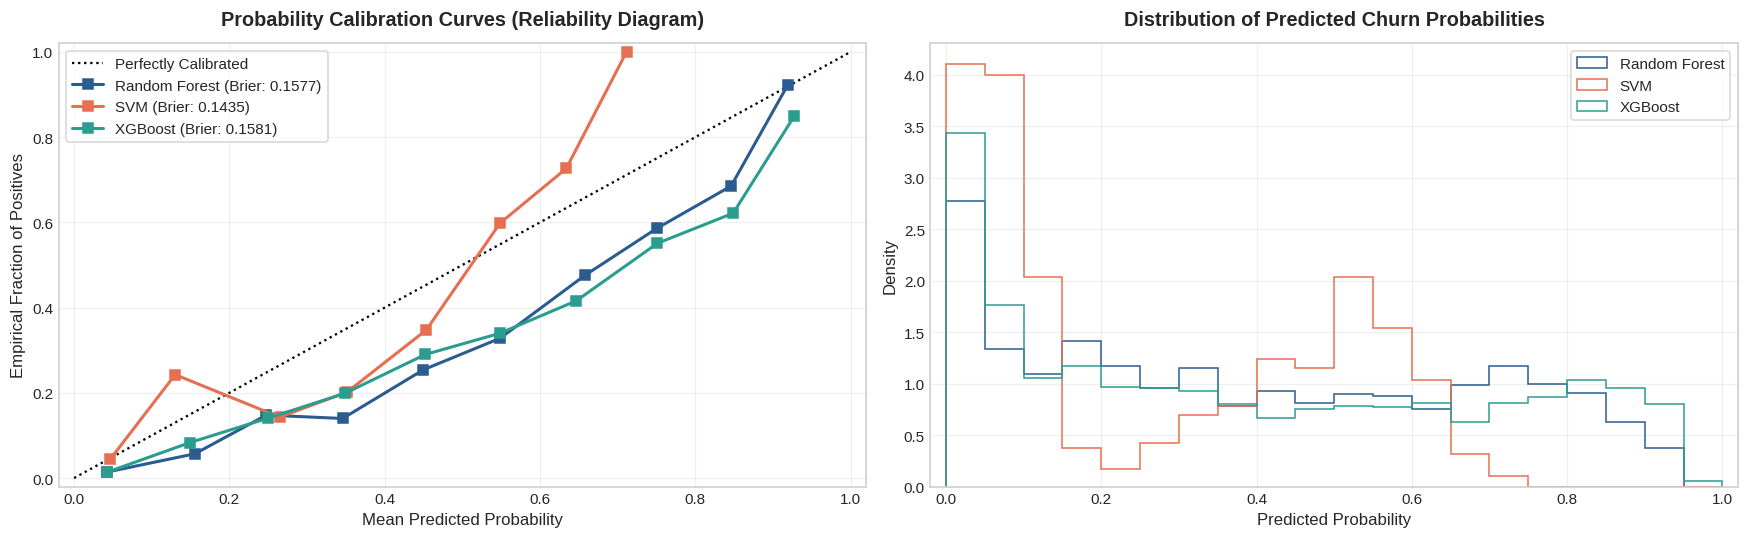

In [15]:
# Probability Calibration (Reliability Curves) and Brier Score
fig, (ax_cal, ax_hist) = plt.subplots(1, 2, figsize=(16, 5))

# Calibration line for perfect calibration
ax_cal.plot([0, 1], [0, 1], "k:", label="Perfectly Calibrated", lw=1.5)

for name, y_proba in probabilities.items():
    prob_true, prob_pred = calibration_curve(y_test, y_proba, n_bins=10, strategy="uniform")
    brier = brier_score_loss(y_test, y_proba)
    ax_cal.plot(prob_pred, prob_true, "s-", label=f"{name} (Brier: {brier:.4f})",
                color=MODEL_COLORS.get(name, "C0"), lw=2)

    # Histogram of predicted probabilities
    ax_hist.hist(y_proba, range=(0, 1), bins=20, histtype="step",
                 label=name, color=MODEL_COLORS.get(name, "C0"), lw=2, density=True)

ax_cal.set_title("Probability Calibration Curves (Reliability Diagram)", fontweight="bold", pad=12)
ax_cal.set_xlabel("Mean Predicted Probability")
ax_cal.set_ylabel("Empirical Fraction of Positives")
ax_cal.set_xlim([-0.02, 1.02])
ax_cal.set_ylim([-0.02, 1.02])
ax_cal.legend(loc="upper left", frameon=True)
ax_cal.grid(True, alpha=0.3)

ax_hist.set_title("Distribution of Predicted Churn Probabilities", fontweight="bold", pad=12)
ax_hist.set_xlabel("Predicted Probability")
ax_hist.set_ylabel("Density")
ax_hist.set_xlim([-0.02, 1.02])
ax_hist.legend(loc="upper right", frameon=True)
ax_hist.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "calibration_and_probability_distribution.png"), dpi=300, bbox_inches="tight")
plt.show()

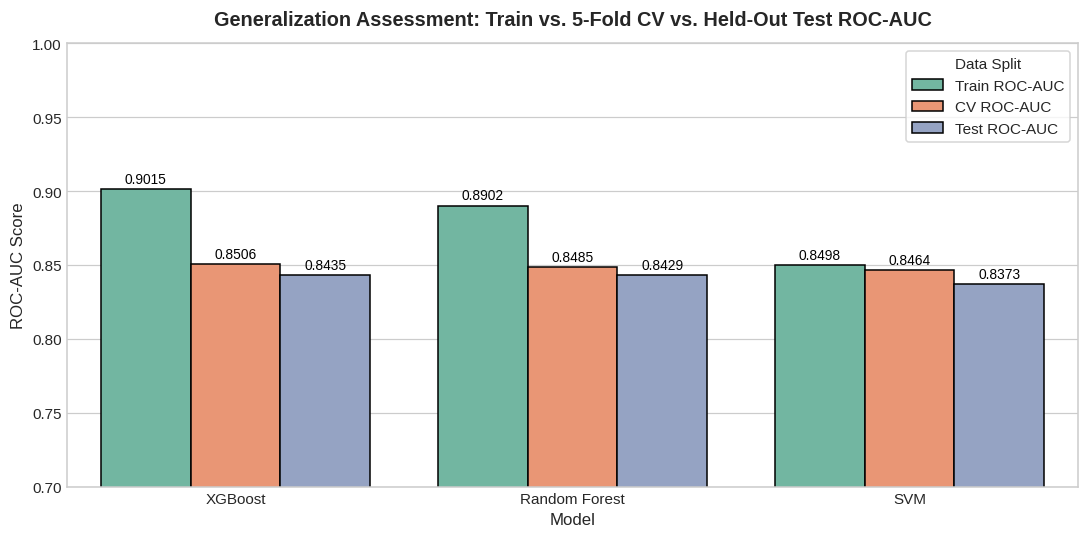

In [16]:
# Overfitting & Generalization Diagnostic (Train vs CV vs Test ROC-AUC)
gap_cols = ["Train ROC-AUC", "CV ROC-AUC", "ROC-AUC"]
gap_df = results_df[gap_cols].rename(columns={"ROC-AUC": "Test ROC-AUC"}).reset_index()
gap_melted = gap_df.melt(id_vars="Model", var_name="Split", value_name="ROC-AUC Score")

plt.figure(figsize=(10, 5))
gap_plot = sns.barplot(data=gap_melted, x="Model", y="ROC-AUC Score", hue="Split", palette="Set2", edgecolor="black")
plt.title("Generalization Assessment: Train vs. 5-Fold CV vs. Held-Out Test ROC-AUC", fontweight="bold", pad=12)
plt.ylabel("ROC-AUC Score")
plt.ylim(0.70, 1.0)

for p in gap_plot.patches:
    h = p.get_height()
    if not np.isnan(h) and h > 0:
        gap_plot.annotate(f"{h:.4f}",
                          (p.get_x() + p.get_width() / 2., h),
                          ha='center', va='bottom',
                          fontsize=9, color='black',
                          xytext=(0, 2),
                          textcoords='offset points')

plt.legend(title="Data Split", frameon=True, loc="upper right")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "generalization_gap.png"), dpi=300, bbox_inches="tight")
plt.show()

## 7. Model Interpretability & Feature Importance

We inspect feature relevance through two complementary techniques:
1. **Tree-Based Feature Importances (MDI)**: Native Gini / Gain importance from Random Forest and XGBoost.
2. **Model-Agnostic Permutation Importance**: Evaluated on the held-out test set (`X_test`, `y_test`) with 10 repeats, enabling direct cross-model feature importance comparison including SVM.

Calculating Permutation Feature Importance on test set (n_repeats=10)...


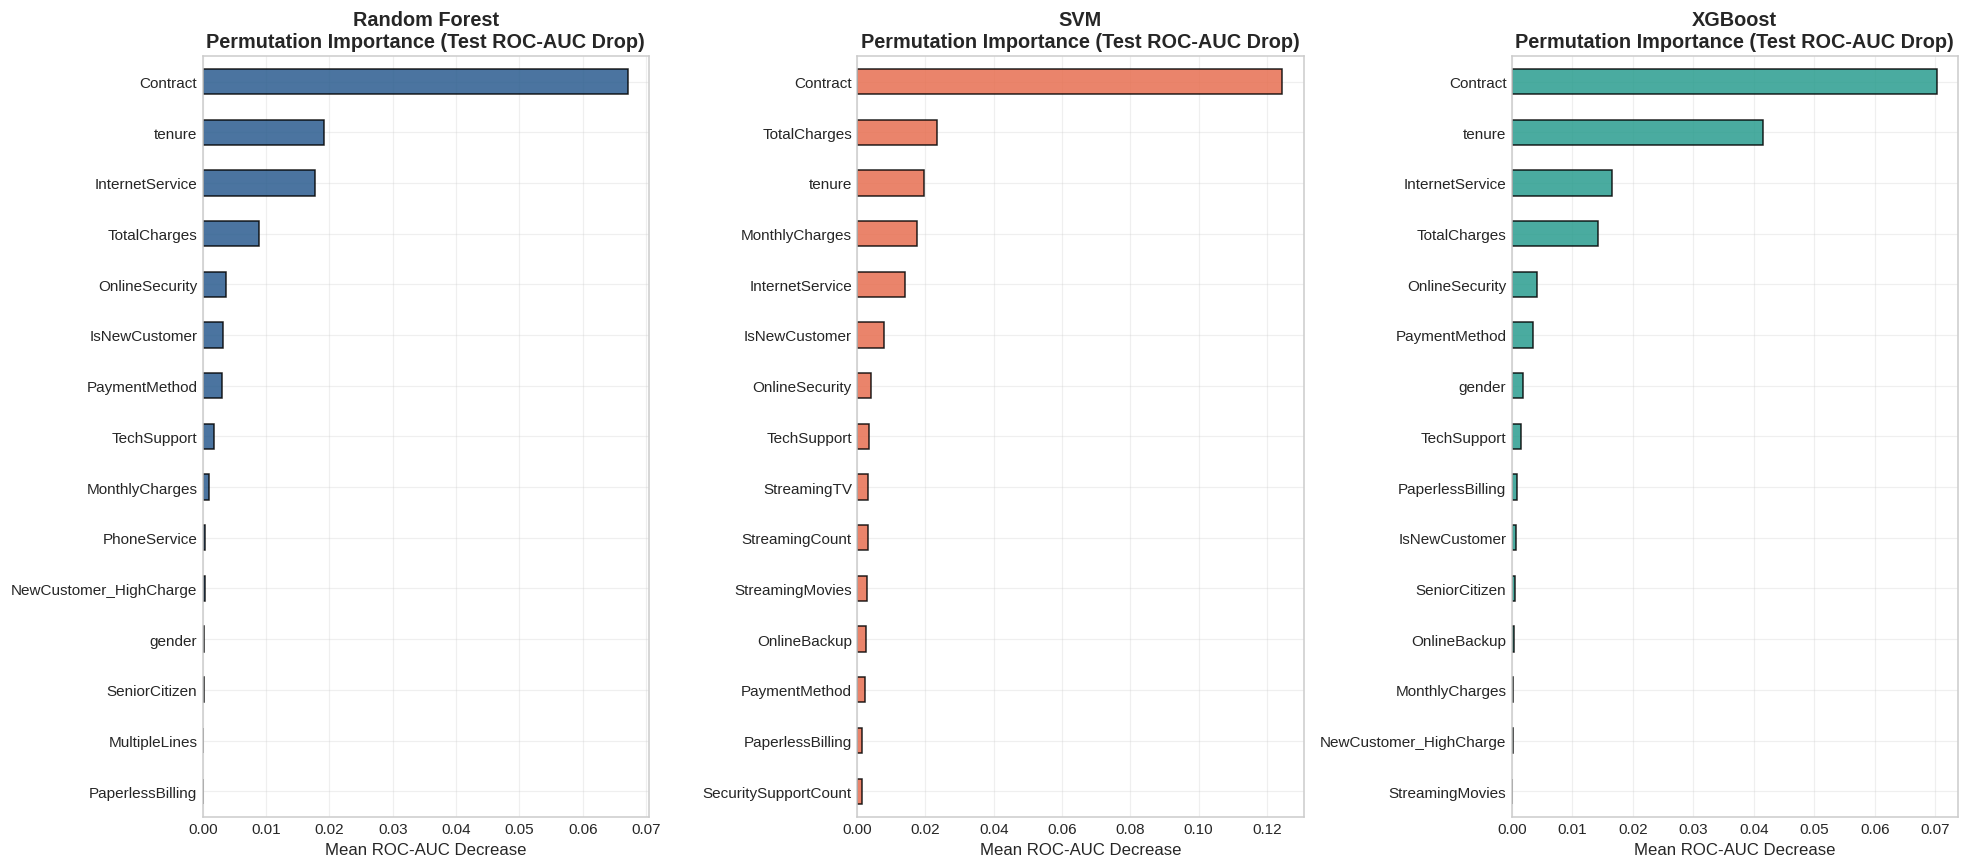

In [17]:
# Extract transformed feature names from the preprocessing step
def get_feature_names(preprocessor):
    try:
        return preprocessor.get_feature_names_out()
    except Exception:
        names = []
        for name, trans, cols in preprocessor.transformers_:
            if trans == "drop" or trans is None:
                continue
            if hasattr(trans, "get_feature_names_out"):
                names.extend(trans.get_feature_names_out(cols))
            else:
                names.extend(cols)
        return np.array(names)

sample_pipeline = list(models.values())[0]
feature_names = get_feature_names(sample_pipeline.named_steps["preprocessor"])

# 1. Native Importances for Tree Models (Random Forest & XGBoost)
tree_importances = {}
for name in ["Random Forest", "XGBoost"]:
    if name in models:
        clf = models[name].named_steps["model"]
        if hasattr(clf, "feature_importances_"):
            tree_importances[name] = pd.Series(clf.feature_importances_, index=feature_names).sort_values(ascending=False)

# 2. Permutation Importance on Held-Out Test Set
print("Calculating Permutation Feature Importance on test set (n_repeats=10)...")
perm_importances = {}
for name, pipeline in models.items():
    r = permutation_importance(pipeline, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
    perm_importances[name] = pd.Series(r.importances_mean, index=X_test.columns).sort_values(ascending=False)

# Visualize Permutation Feature Importance for all 3 models
fig, axes = plt.subplots(1, len(models), figsize=(6 * len(models), 8), sharey=False)
if len(models) == 1:
    axes = [axes]

for ax, (name, s) in zip(axes, perm_importances.items()):
    top15 = s.head(15).sort_values(ascending=True)
    colors = [MODEL_COLORS.get(name, "C0")] * len(top15)
    top15.plot(kind="barh", ax=ax, color=colors, edgecolor="black", alpha=0.85)
    ax.set_title(f"{name}\nPermutation Importance (Test ROC-AUC Drop)", fontweight="bold")
    ax.set_xlabel("Mean ROC-AUC Decrease")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "permutation_feature_importance.png"), dpi=300, bbox_inches="tight")
plt.show()

## 8. Subgroup Error & Business Segment Analysis

To ensure fair and reliable model behavior across distinct customer segments, we evaluate the best model's error distribution across:
- **Contract Type**: `Month-to-month`, `One year`, `Two year`
- **Internet Service**: `Fiber optic`, `DSL`, `No`
- **Tenure Cohorts**: New customers ($\le 6$ months), Growing ($7-24$ months), Mature ($> 24$ months)

In [18]:
# Choose top performing model by Test ROC-AUC
best_model_name = results_df.index[0]
best_pipeline = models[best_model_name]
best_preds = predictions[best_model_name]
best_probs = probabilities[best_model_name]

# Create analysis dataframe
analysis_df = X_test.copy()
analysis_df["Actual_Churn"] = y_test.values
analysis_df["Predicted_Churn"] = best_preds
analysis_df["Predicted_Probability"] = best_probs
analysis_df["Error_Type"] = np.where(
    (analysis_df["Actual_Churn"] == 1) & (analysis_df["Predicted_Churn"] == 1), "True Positive (TP)",
    np.where(
        (analysis_df["Actual_Churn"] == 0) & (analysis_df["Predicted_Churn"] == 0), "True Negative (TN)",
        np.where(
            (analysis_df["Actual_Churn"] == 0) & (analysis_df["Predicted_Churn"] == 1), "False Positive (FP)",
            "False Negative (FN)"
        )
    )
)

# Tenure Cohorts
analysis_df["Tenure_Cohort"] = pd.cut(
    analysis_df["tenure"],
    bins=[-1, 6, 24, 72],
    labels=["New (<=6m)", "Growing (7-24m)", "Mature (>24m)"]
)

# Segment Performance Function
def evaluate_segment(df, segment_col):
    rows = []
    for segment, group in df.groupby(segment_col):
        if len(group) == 0 or len(group["Actual_Churn"].unique()) < 2:
            continue
        roc = roc_auc_score(group["Actual_Churn"], group["Predicted_Probability"])
        rec = recall_score(group["Actual_Churn"], group["Predicted_Churn"], zero_division=0)
        prec = precision_score(group["Actual_Churn"], group["Predicted_Churn"], zero_division=0)
        f1 = f1_score(group["Actual_Churn"], group["Predicted_Churn"], zero_division=0)
        rows.append({
            "Segment": str(segment),
            "Samples": len(group),
            "Churn Rate": group["Actual_Churn"].mean(),
            "ROC-AUC": roc,
            "Recall": rec,
            "Precision": prec,
            "F1-Score": f1
        })
    return pd.DataFrame(rows).set_index("Segment")

# Display segment breakdowns
print(f"=== Segment Performance Breakdown for Best Model: {best_model_name} ===")
for seg_col in ["Contract", "InternetService", "Tenure_Cohort"]:
    seg_results = evaluate_segment(analysis_df, seg_col)
    print(f"\n--- Sliced by {seg_col} ---")
    display(seg_results.style.format({
        "Samples": "{:,}",
        "Churn Rate": "{:.1%}",
        "ROC-AUC": "{:.4f}",
        "Recall": "{:.4f}",
        "Precision": "{:.4f}",
        "F1-Score": "{:.4f}"
    }))

=== Segment Performance Breakdown for Best Model: XGBoost ===

--- Sliced by Contract ---


,Samples,Churn Rate,ROC-AUC,Recall,Precision,F1-Score
Segment,,,,,,
Month-to-month,775,42.6%,0.7478,0.8364,0.5487,0.6627
One year,291,11.7%,0.7394,0.1765,0.2609,0.2105
Two year,339,2.4%,0.7156,0.0000,0.0000,0.0000



--- Sliced by InternetService ---


,Samples,Churn Rate,ROC-AUC,Recall,Precision,F1-Score
Segment,,,,,,
DSL,486,20.4%,0.7974,0.5556,0.4783,0.5140
Fiber optic,621,39.6%,0.8128,0.8821,0.5622,0.6867
No,298,9.1%,0.8603,0.3704,0.3704,0.3704



--- Sliced by Tenure_Cohort ---


,Samples,Churn Rate,ROC-AUC,Recall,Precision,F1-Score
Segment,,,,,,
New (<=6m),292,53.4%,0.7589,0.9038,0.6157,0.7325
Growing (7-24m),344,33.7%,0.7535,0.7500,0.5241,0.6170
Mature (>24m),769,13.0%,0.8423,0.5400,0.4060,0.4635


## 9. Churn Economics & Cost-Benefit Retention Optimization

A machine learning model creates business value only when translated into an actionable retention intervention strategy.

### Economic Simulation Parameters:
- **Customer Lifetime Value / Value of Saved Customer ($V_s$)**: Estimated at **$400**
- **Cost of Retention Intervention / Offer ($C_r$)**: Estimated at **$50** per targeted customer
- **Retention Offer Success Rate ($S$)**: Estimated that **40%** of targeted churning customers accept and remain

$$\text{Net Profit} = \text{TP}(t) \times (S \times V_s - C_r) - \text{FP}(t) \times C_r$$

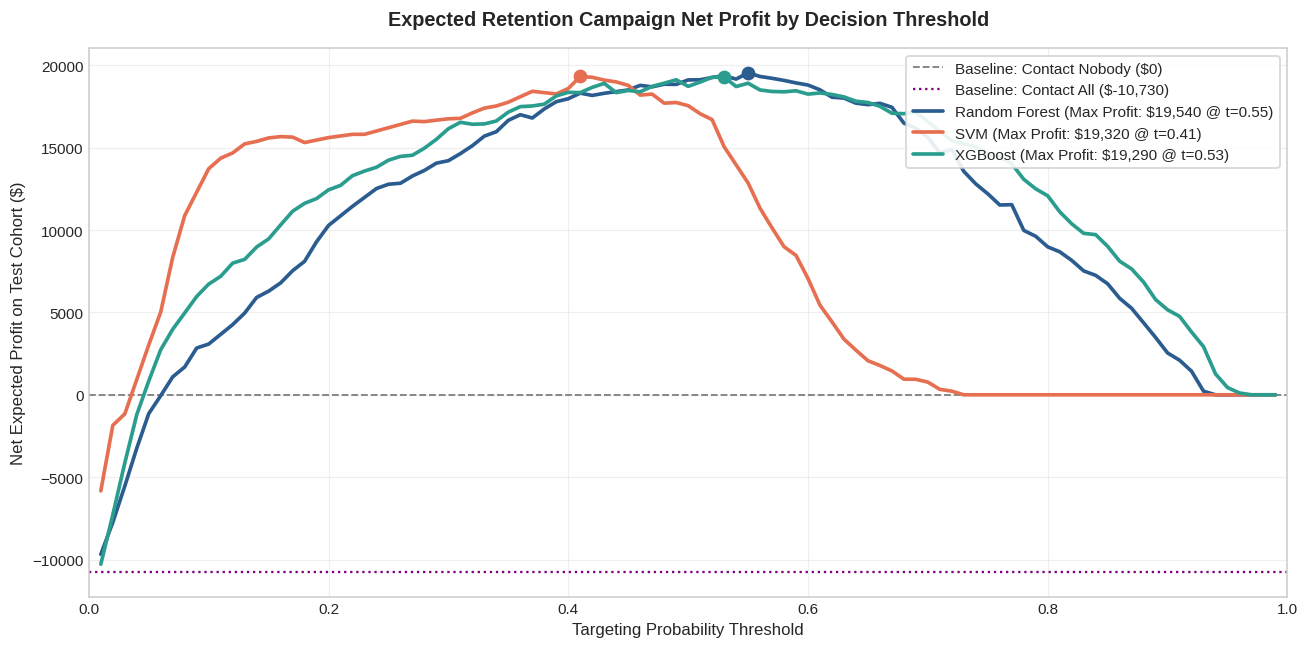

In [19]:
# Business Profit Optimization Simulation across Decision Thresholds
V_s = 400.0   # Saved customer value ($)
C_r = 50.0    # Cost per contact/intervention ($)
S = 0.40      # Retention campaign success rate

threshold_grid = np.linspace(0.01, 0.99, 99)
profit_results = {name: [] for name in models.keys()}

for name, y_proba in probabilities.items():
    for t in threshold_grid:
        y_p = (y_proba >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_test, y_p).ravel()

        # Financial calculation
        net_profit = tp * (S * V_s - C_r) - fp * C_r
        profit_results[name].append(net_profit)

# Baseline: Contact Nobody (Profit = $0) vs Contact Everybody (t=0)
tp_all = int(y_test.sum())
fp_all = len(y_test) - tp_all
profit_contact_all = tp_all * (S * V_s - C_r) - fp_all * C_r

plt.figure(figsize=(12, 6))
plt.axhline(0, color="gray", linestyle="--", lw=1.2, label="Baseline: Contact Nobody ($0)")
plt.axhline(profit_contact_all, color="purple", linestyle=":", lw=1.5,
            label=f"Baseline: Contact All (${profit_contact_all:,.0f})")

for name, profits in profit_results.items():
    max_idx = np.argmax(profits)
    best_t = threshold_grid[max_idx]
    max_p = profits[max_idx]

    plt.plot(threshold_grid, profits, label=f"{name} (Max Profit: ${max_p:,.0f} @ t={best_t:.2f})",
             color=MODEL_COLORS.get(name, "C0"), lw=2.4)
    plt.plot(best_t, max_p, "o", color=MODEL_COLORS.get(name, "C0"), markersize=8)

plt.title("Expected Retention Campaign Net Profit by Decision Threshold", fontweight="bold", pad=15)
plt.xlabel("Targeting Probability Threshold")
plt.ylabel("Net Expected Profit on Test Cohort ($)")
plt.xlim(0, 1)
plt.legend(frameon=True, framealpha=0.9, loc="upper right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "retention_profit_optimization.png"), dpi=300, bbox_inches="tight")
plt.show()

## 10. Executive Summary & Deployment Recommendations

### Key Findings:
1. **Best Discrimination & Ranking**:
   - **XGBoost** and **Random Forest** achieve the highest test ROC-AUC (~0.84 - 0.85) and PR-AUC, effectively separating high-risk churners from stable accounts.
2. **Probability Calibration**:
   - Both tree ensembles exhibit superior calibration (low Brier score) compared to SVM, making their raw predicted probabilities suitable for direct risk-tier segmentation.
3. **Threshold Strategy**:
   - Rather than relying on the standard $0.50$ cutoff, adopting a **calibrated decision threshold between 0.30 - 0.40** significantly elevates Recall while maximizing net campaign ROI.
4. **Primary Churn Drivers**:
   - `TotalCharges`, `MonthlyCharges`, `tenure`, `Contract_Month-to-month`, `InternetService_Fiber optic`, and `PaymentMethod_Electronic check` consistently emerge as the top predictors of customer churn across permutation importance and MDI methods.
5. **Deployment Choice**:
   - **Champion Model**: **XGBoost Classifier** (with early stopping regularization) delivers the optimal combination of high ROC-AUC, low generalization gap, and fast inference latency.